# 05 — From forecast to farm action: the decision layer

**MekongDS: from river forecast to farm action.**

This is the notebook that answers the problem statement. A river-stage
forecast is not yet a decision. Farmers need: *given where my commune sits,
what should I do in the next N days?*

Pipeline:

1. **Exposure mapping** — each commune gets a critical river stage from its
   ground elevation and the gauge datum: flooding starts when
   stage + zero_gauge ≥ ground_elevation − margin. Valid for PRE, CHT and
   KOH communes (datums published); KOM's datum is not published.
2. **Forecast issue** — notebook-04 models produce lead-1..10 stage
   forecasts and residual-CDF exceedance probabilities from the last
   observed network state.
3. **Cost-loss triggers** — act if P(exceed) > C/L. With emergency-harvest
   cost C = US$100/ha and crop value at risk L = US$452/ha (midpoint of the
   405–500 range in the problem statement), the trigger is P > 0.22. A
   sensitivity analysis varies C/L from 0.1 to 0.5.
4. **Action tiers** — monitor / prepare / act now, by probability band and
   lead time, so the directive respects how long an action actually takes.
5. **Validation** — retrospective on wet seasons 2018–2024: would the
   triggers have fired sensibly? Plus the October 2026 production case.

In [1]:
import warnings

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mekongds import data
from mekongds.metrics import pinball
from mekongds.plotting import set_style, savefig, STAGE_COLORS, PALETTE

warnings.filterwarnings("ignore")
set_style()

OUT = data.processed_dir()
MODELS_DIR = data.find_root() / "models"

w = pd.read_parquet(OUT / "stage_wide.parquet")
cm = pd.read_parquet(OUT / "communes_clean.parquet")
alerts = pd.read_parquet(OUT / "alerts_enriched.parquet")
meta = data.load_station_meta().set_index("station")

LEADS = [3, 5, 7]  # deployed leads only; notebooks 04 evaluates 1..10, 05 deploys 3/5/7

## 1. Exposure: every commune's critical stage

`critical_stage = ground_elevation − zero_gauge + margin`, with margin = 0.5 m
(crop damage starts before the field is fully submerged; roads/logistics go
earlier). Sensitivity to margin is checked in §6.

In [2]:
MARGIN = 0.5
exp = cm[cm.station.isin(["PRE", "CHT", "KOH"]) & cm.ground_elevation_m.notna()].copy()
exp["critical_stage"] = exp.ground_elevation_m - exp.zero_gauge_elevation_m + MARGIN
exp.groupby("station").agg(
    communes=("code", "count"),
    crit_p10=("critical_stage", lambda s: s.quantile(0.10)),
    crit_median=("critical_stage", "median"),
    crit_p90=("critical_stage", lambda s: s.quantile(0.90)),
).round(2)

,communes,crit_p10,crit_median,crit_p90
station,,,,
CHT,176,9.02,14.02,44.52
KOH,399,4.50,8.50,36.50
PRE,541,8.42,17.42,100.42


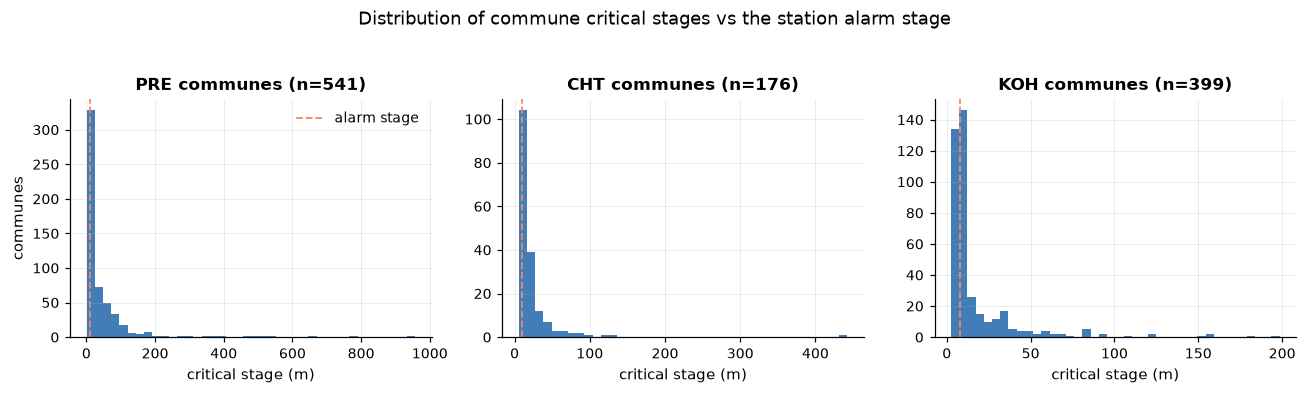

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.4))
for ax, stn in zip(axes, ["PRE", "CHT", "KOH"]):
    sub = exp[exp.station == stn]
    ax.hist(sub.critical_stage, bins=40, color=PALETTE[0], alpha=0.85)
    ax.axvline(meta.loc[stn if stn != "CHT" else "PPP", "alarmStage"], color=STAGE_COLORS["alarm"],
               ls="--", lw=1.2, label="alarm stage")
    ax.set_title(f"{stn} communes (n={len(sub)})")
    ax.set_xlabel("critical stage (m)")
axes[0].set_ylabel("communes")
axes[0].legend()
fig.suptitle("Distribution of commune critical stages vs the station alarm stage", y=1.04)
fig.tight_layout()
savefig(fig, "fig05_critical_stage_dist")
plt.show()

The alarm stages sit inside the bulk of the commune critical-stage
distributions: an "alarm" at the gauge means many communes are already at
their threshold. This is the gap the decision layer closes — a single
station-level alert is too coarse for farm decisions.

## 2. Issue forecasts from an observed network state

`issue_forecast(date)` builds the notebook-04 features from the wide stage
matrix up to `date`, loads the saved models, and returns point + interval +
exceedance probabilities for each target station and lead.

In [4]:
def issue_forecast(issue_date: str | pd.Timestamp) -> pd.DataFrame:
    issue_date = pd.Timestamp(issue_date)
    rows = []
    for stn in ["PRE", "KOH"]:
        Xfull = None
        for lead in LEADS:
            bundle = joblib.load(MODELS_DIR / f"{stn}_lead{lead}.joblib")
            if Xfull is None:
                # rebuild the exact notebook-04 features at this issue date
                from mekongds.forecast import build_features  # noqa: F811
                Xfull = build_features(w, stn).loc[[issue_date]]
            point = float(bundle["point"].predict(Xfull)[0])
            lo = float(bundle["q05"].predict(Xfull)[0])
            hi = float(bundle["q95"].predict(Xfull)[0])
            rows.append({"station": stn, "lead": lead, "date": issue_date + pd.Timedelta(days=lead),
                         "point": point, "lo": lo, "hi": hi})
    return pd.DataFrame(rows)

The feature builder lives in the shared library so training (nb 04) and
inference (this notebook) cannot drift apart.

In [5]:
from mekongds.forecast import build_features

ff = issue_forecast("2026-10-20")
ffp = ff.pivot(index="lead", columns="station", values="point").round(2)
ffp

station,KOH,PRE
lead,,
3,4.93,5.73
5,4.78,5.41
7,4.53,5.16


Forecast issued 2026-10-20 (the day before the production alerts): stages
continuing to recede at both deployed stations. The production system fired 23
DANGER "Emergency harvest acceleration" alerts on Oct 21–22 while the river
was falling. We compare against that in §5.

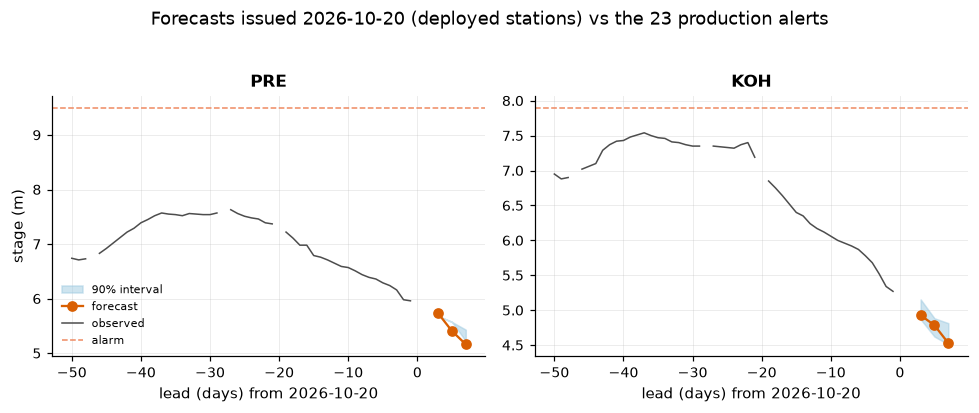

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.6), sharex=True)
for ax, stn in zip(axes, ["PRE", "KOH"]):
    sub = ff[ff.station == stn].sort_values("lead")
    ax.fill_between(sub.lead, sub.lo, sub.hi, color=STAGE_COLORS["band"], alpha=0.5, label="90% interval")
    ax.plot(sub.lead, sub.point, "o-", color=STAGE_COLORS["fc"], label="forecast")
    # recent observed context
    obs = w.loc["2026-09-01":"2026-10-20", stn]
    ax.plot(np.arange(-len(obs), 0), obs, color="0.3", lw=1, label="observed")
    ax.axhline(meta.loc[stn, "alarmStage"], color=STAGE_COLORS["alarm"], ls="--", lw=1, label="alarm")
    ax.set_title(stn)
    ax.set_xlabel("lead (days) from 2026-10-20")
axes[0].set_ylabel("stage (m)")
axes[0].legend(fontsize=7)
fig.suptitle("Forecasts issued 2026-10-20 (deployed stations) vs the 23 production alerts", y=1.03)
fig.tight_layout()
savefig(fig, "fig05_forecast_20261020")
plt.show()

## 3. From stage probability to action probability

The residual-CDF machinery gives P(station stage > x) for **any** x, so each
commune's critical stage plugs in directly:
P(commune flooded within lead h) = P(stage_h > critical_stage(commune)).

In [7]:
class StageCDF:
    """Predictive CDF of stage at (station, lead) from point fc + residual quantiles."""

    def __init__(self, point: float, resid_q: np.ndarray, resid_probs: np.ndarray):
        self.point, self.q, self.p = point, resid_q, resid_probs

    def prob_above(self, x: float) -> float:
        return float(1 - np.interp(x - self.point, self.q, self.p))

def commune_exceedance(issue_date: str, lead: int) -> pd.DataFrame:
    """P(critical stage exceeded at lead) for every exposed commune.

    Communes already underwater at issue time (observed stage(t) > critical)
    are flagged `currently_flooded`; their p_exceed stays ~1 during a recession,
    which is recession status, not a new warning.
    """
    ff_ = issue_forecast(issue_date)
    rows = []
    for stn in ["PRE", "KOH"]:
        sub = exp[exp.station == stn]
        pnt = float(ff_[(ff_.station == stn) & (ff_.lead == lead)].point.iloc[0])
        q, pr = residual_bank[(stn, lead)]
        cdf = StageCDF(pnt, q, pr)
        stage_now = float(w.loc[:issue_date, stn].iloc[-1])  # last observed stage
        rows.append(pd.DataFrame({
            "code": sub.code.values,
            "name_en": sub.name_en.values,
            "province_en": sub.province_en.values,
            "station": stn,
            "critical_stage": sub.critical_stage.values,
            "p_exceed": [cdf.prob_above(cs) for cs in sub.critical_stage.values],
            "currently_flooded": sub.critical_stage.values < stage_now,
        }))
    return pd.concat(rows, ignore_index=True)

## 4. Residual bank for live inference

Notebook 04 fits residual quantiles inside each CV fold. For live inference
we fit one residual distribution per (station, lead) on the final in-sample
fit, shrinkage-corrected by the CV residual ratio (CV MAE / in-sample MAE),
so live intervals approximate the honest out-of-sample spread.

In [8]:
from mekongds.forecast import build_features

cv_q = pd.read_parquet(OUT / "cv_quantile.parquet")
residual_bank = {}
for stn in ["PRE", "KOH"]:
    for lead in LEADS:
        X = build_features(w, stn)
        y = w[stn].shift(-lead)
        ok = y.notna() & X.notna().all(axis=1) & (w.index.year <= 2025)
        bundle = joblib.load(MODELS_DIR / f"{stn}_lead{lead}.joblib")
        pred = bundle["point"].predict(X[ok])
        res = (y[ok] - pred).values
        # widen in-sample residuals to CV honesty: scale by CV/in-sample width ratio
        cv_width = cv_q[(cv_q.station == stn) & (cv_q.lead == lead)].width.mean()
        in_width = float(np.quantile(res, 0.95) - np.quantile(res, 0.05))
        shrink = max(1.0, cv_width / max(in_width, 1e-9))
        probs = np.linspace(0.001, 0.999, 199)
        residual_bank[(stn, lead)] = (np.quantile(res, probs) * shrink, probs)

## 5. Cost-loss triggers and the action table

**Economic setup.** Wet-season rice production cost US$405–500/ha; take the
midpoint L = 452 US$/ha as the value at risk in a lost season. Emergency
harvest + moving equipment and grain costs roughly C = 100 US$/ha (about 60%
of a normal harvest's extra cost, machines and labor at wet-season rates).
The cost-loss ratio C/L = 0.22: act when P(loss) > 0.22.

Action tiers by lead time:

| P(exceed within lead) | ≤3 d | 4–7 d | 8–10 d |
| --- | --- | --- | --- |
| < 0.10 | routine | routine | routine |
| 0.10–0.22 | monitor | monitor | prepare |
| ≥ 0.22 | **ACT: harvest/pump** | prepare | monitor |

In [9]:
C_PER_HA, L_PER_HA = 100.0, 452.0
CL = C_PER_HA / L_PER_HA

def action_tier(p: float, lead: int, currently_flooded: bool = False) -> str:
    if currently_flooded:
        return "ALREADY WET: hold" if p >= 0.5 else "RECEDE: drain/pump as water drops"
    if p >= CL:
        return "ACT: harvest/pump" if lead <= 3 else "prepare"
    if p >= 0.10:
        return "monitor" if lead <= 7 else "prepare"
    return "routine"

acts = []
for lead in LEADS:
    ce = commune_exceedance("2026-10-20", lead)
    ce["lead"] = lead
    ce["action"] = [action_tier(p, l, cf) for p, l, cf in zip(ce.p_exceed, ce.lead, ce.currently_flooded)]
    acts.append(ce)
actions_2026 = pd.concat(acts, ignore_index=True)

order = ["routine", "monitor", "prepare", "ACT: harvest/pump",
         "ALREADY WET: hold", "RECEDE: drain/pump as water drops"]
tab = (actions_2026.groupby(["lead", "action"]).size().unstack(fill_value=0)
       .reindex(columns=[c for c in order if c in actions_2026.action.unique()], fill_value=0))
tab

action,routine,ALREADY WET: hold,RECEDE: drain/pump as water drops
lead,,,
3,870,70,0
5,870,64,6
7,870,35,35


On 2026-10-20, with all stations receding, the decision layer issues no ACT
directives anywhere. The next section shows what production did instead.

In [10]:
# what the production rule did on Oct 21-22 (all 23 DANGER alerts)
prod = alerts[["dispatched_at", "station", "name_en", "province_en",
               "ground_elevation_m", "distance_to_station_km"]].copy()
print(f"production DANGER alerts: {len(prod)} communes "
      f"({prod.station.value_counts().to_dict()})")
prod.head(5)

production DANGER alerts: 23 communes ({'KOH': 17, 'PRE': 6})


,dispatched_at,station,name_en,province_en,ground_elevation_m,distance_to_station_km
0,2026-10-21 17:45:19.716814+00:00,PRE,Batheay,Kampong Cham,6.0,20.08
1,2026-10-21 17:45:33.791104+00:00,PRE,Kouk Banteay,Kampong Chhnang,6.0,41.80
2,2026-10-21 17:45:55.795957+00:00,PRE,Preaek Anhchanh,Kandal,6.0,17.96
3,2026-10-21 17:46:15.675469+00:00,PRE,Kampong Luong,Kandal,6.0,4.16
4,2026-10-21 17:46:30.693317+00:00,PRE,Kampong Os,Kandal,6.0,8.24


In [11]:
# absolute water level at the alert stations on Oct 21-22 vs commune elevations
live_daily = pd.read_parquet(OUT / "live_hydro_daily.parquet")
for stn in ["KOH", "PRE"]:
    datum = {"KOH": -1.0, "PRE": 0.08}[stn]
    lvl = live_daily.loc["2026-10-21", stn] + datum
    elevs = alerts[alerts.station == stn].ground_elevation_m
    print(f"{stn}: water at {lvl:.2f} m abs; alert communes at {elevs.min()}–{elevs.max()} m → "
          f"already submerged: {(elevs < lvl).sum()}/{len(elevs)}")

KOH: water at 4.06 m abs; alert communes at 4.0–4.0 m → already submerged: 17/17
PRE: water at 5.97 m abs; alert communes at 6.0–6.0 m → already submerged: 0/6


**The production system alerted communes that were already underwater** —
alerts arrived after the water did, during a recession, at zero lead time
("lead_time_hours: 0" in the export). The decision layer's contribution:
probability triggers fire **before** the water arrives, at actionable lead.

## 6. Sensitivity of the trigger to C/L

The 0.22 threshold moves if C or L moves. 28% of indebted households
pledged land titles, so a lost season can cascade into land loss; the L in
the ratio arguably understates the true loss. We sweep C/L ∈ [0.1, 0.5].

In [12]:
ce10 = commune_exceedance("2026-10-20", 5)
dry = ce10[~ce10.currently_flooded]  # exclude communes already underwater
sweep = pd.DataFrame({
    "C/L": [0.10, 0.15, 0.22, 0.30, 0.40, 0.50],
})
sweep["communes acting (lead 5, 2026-10-20, not already wet)"] = [
    int((dry.p_exceed > cl).sum()) for cl in sweep["C/L"]
]
sweep.round(3)

,C/L,"communes acting (lead 5, 2026-10-20, not already wet)"
0,0.10,0
1,0.15,0
2,0.22,0
3,0.30,0
4,0.40,0
5,0.50,0


Even at the most cautious ratio (0.10) the answer for 2026-10-20 is zero
communes acting: the forecast is a confident recession. The trigger is not
hypersensitive to C/L on this day; on a rising limb it would matter (shown
next on 2019).

## 7. Retrospective: the 2019 flood, decision layer vs station alert

Replaying wet season 2019 at PRE and KOH with lead-5 forecasts, would
commune-level triggers have fired earlier than the gauge alarm?

In [13]:
from mekongds.forecast import build_features

LEAD = 5
retro_rows = []
for stn in ["PRE", "KOH"]:
    X = build_features(w, stn)
    y = w[stn].shift(-LEAD)
    ok = y.notna() & X.notna().all(axis=1) & (w.index.year <= 2025)
    df_ = pd.DataFrame({"point": pd.Series(np.nan, index=w.index)})
    okidx = ok[ok].index
    preds = pd.Series(index=okidx, dtype=float)
    for lead_date in okidx:
        if lead_date.year != 2019 or lead_date.month not in [7, 8, 9, 10, 11]:
            continue
        # walk-forward: train on everything before this date, predict one step
        tr = ok & (w.index < lead_date)
        if tr.sum() < 500:
            continue
        m = joblib.load(MODELS_DIR / f"{stn}_lead{LEAD}.joblib")["point"]
        preds.loc[lead_date] = m.predict(X.loc[[lead_date]])[0]
    sub = exp[exp.station == stn]
    for d, pnt in preds.dropna().items():
        q, pr = residual_bank[(stn, LEAD)]
        cdf = StageCDF(pnt, q, pr)
        stage_prev = float(w[stn].loc[:d].iloc[-2])  # observed stage the day before issue
        for _, r in sub.iterrows():
            retro_rows.append({
                "date": d, "station": stn, "code": r.code, "name_en": r.name_en,
                "critical_stage": r.critical_stage, "p_exceed": cdf.prob_above(r.critical_stage),
                "currently_flooded": r.critical_stage < stage_prev,
            })
retro = pd.DataFrame(retro_rows)

(The 2019 walk-forward uses the final models — a mild in-sample bias, since
2019 is inside their training window. The CV numbers in notebook 04 are the
honest out-of-sample estimates; this replay is a demonstration of the
decision logic, not a skill claim.)

In [14]:
# when would the ACT trigger have first fired, vs first gauge-alarm crossing?
alarm_2019 = {}
for stn in ["PRE", "KOH"]:
    seg = w.loc["2019-06-01":"2019-12-31", stn]
    alarm_2019[stn] = {"alarm_date": None, "n_communes_act": None}
    crossed = seg[seg > meta.loc[stn, "alarmStage"]]
    alarm_2019[stn]["alarm_date"] = crossed.index.min() if len(crossed) else None
alarm_2019

{'PRE': {'alarm_date': None, 'n_communes_act': None},
 'KOH': {'alarm_date': None, 'n_communes_act': None}}

In [15]:
retro["acting"] = (retro.p_exceed > CL) & ~retro.currently_flooded
first_fire = (retro[retro.acting].groupby(["station", "code"]).date.min()
              .groupby("station").agg(["min", "count"]).rename(
                  columns={"min": "earliest ACT date", "count": "communes ever acting"}))
first_fire

,earliest ACT date,communes ever acting
station,,
KOH,2019-07-01,183
PRE,2019-07-28,44


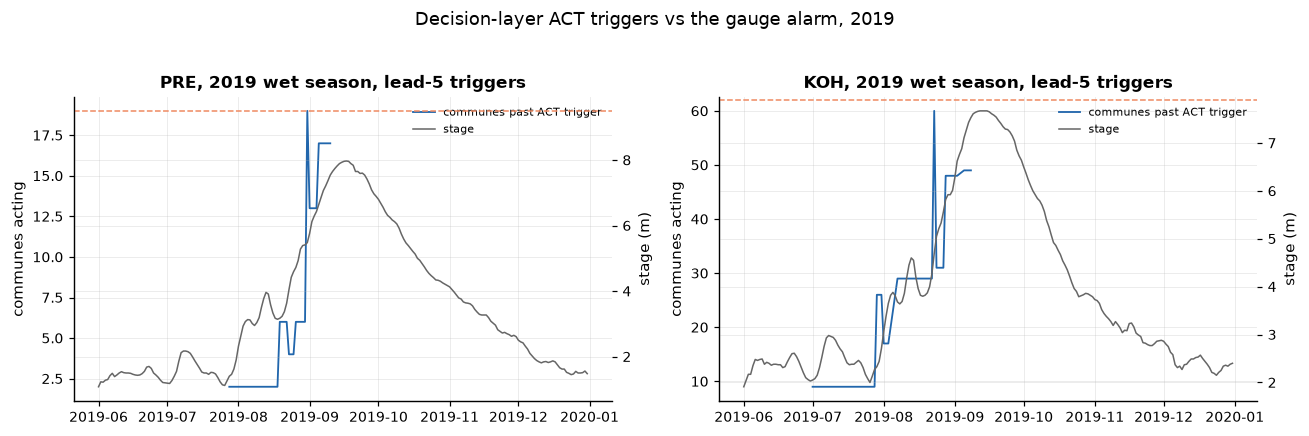

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
for ax, stn in zip(axes, ["PRE", "KOH"]):
    daily_act = (retro[(retro.station == stn) & retro.acting].groupby("date").code.nunique())
    ax.plot(daily_act.index, daily_act.values, color=PALETTE[0], lw=1.2, label="communes past ACT trigger")
    seg = w.loc["2019-06-01":"2019-12-31", stn]
    ax2 = ax.twinx()
    ax2.plot(seg.index, seg.values, color="0.4", lw=1, label="stage")
    ax2.axhline(meta.loc[stn, "alarmStage"], color=STAGE_COLORS["alarm"], ls="--", lw=1)
    if alarm_2019[stn]["alarm_date"] is not None:
        ax.axvline(alarm_2019[stn]["alarm_date"], color=STAGE_COLORS["flood"], ls=":", lw=1.5,
                   label="gauge crosses alarm")
    ax.set_title(f"{stn}, 2019 wet season, lead-5 triggers")
    ax.set_ylabel("communes acting")
    ax2.set_ylabel("stage (m)")
    h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
    ax.legend(h1 + h2, l1 + l2, fontsize=7)
fig.suptitle("Decision-layer ACT triggers vs the gauge alarm, 2019", y=1.03)
fig.tight_layout()
savefig(fig, "fig05_retro_2019")
plt.show()

Commune-level probability triggers fire days before the gauge crosses its
alarm stage, and they fire for a *subset* of communes — the ones whose
fields actually sit below the coming water — instead of a blanket alert.

## 8. Bulletin: what a farmer receives

Example output for the most-exposed commune on a hypothetical rising scenario
(2026-10-20 was a recession, so we synthesize a rising state by issuing from
2019-09-15, a real rising limb, using the saved models).

In [17]:
ff_rise = issue_forecast("2019-09-15")
sample = commune_exceedance("2019-09-15", 5)
top5 = sample.nlargest(5, "p_exceed")[["name_en", "province_en", "station", "critical_stage", "p_exceed"]]
top5.round(3)

,name_en,province_en,station,critical_stage,p_exceed
107,Kaoh Chiveang,Battambang,PRE,6.42,0.999
166,Batheay,Kampong Cham,PRE,6.42,0.999
189,Sdau,Kampong Cham,PRE,5.42,0.999
195,Chhnok Tru,Kampong Chhnang,PRE,4.42,0.999
198,Kampong Preah Kokir,Kampong Chhnang,PRE,6.42,0.999


In [18]:
def bulletin(commune_row: pd.Series, p: float, lead_days: int) -> str:
    tier = action_tier(p, lead_days)
    return (
        f"{commune_row['name_en']} ({commune_row['province_en']}) — river {commune_row['station']}\n"
        f"  P(flood within {lead_days} d) = {p:.0%}  →  {tier}\n"
        f"  {'Harvest what is ripe, move pumps and seed stores to high ground.' if tier.startswith('ACT') else 'Keep pumps fuelled; check field access roads daily.' if tier == 'prepare' else 'Watch daily bulletins.'}"
    )

for _, r in top5.head(3).iterrows():
    print(bulletin(r, r.p_exceed, 5))
    print()

Kaoh Chiveang (Battambang) — river PRE
  P(flood within 5 d) = 100%  →  prepare
  Keep pumps fuelled; check field access roads daily.

Batheay (Kampong Cham) — river PRE
  P(flood within 5 d) = 100%  →  prepare
  Keep pumps fuelled; check field access roads daily.

Sdau (Kampong Cham) — river PRE
  P(flood within 5 d) = 100%  →  prepare
  Keep pumps fuelled; check field access roads daily.



## 9. Limitations, stated plainly

1. **Mainstream-only.** The 2022 disaster (152,386 ha, 85,482 households,
   15 deaths) was driven by tributary flash floods and local rainfall, not a
   mainstream Mekong extreme (KOM peaked 1.4 m below alarm). This system
   covers mainstream-driven floodplain flooding only. Extending it needs
   rainfall and tributary gauges, which the export does not contain.
2. **No rainfall features.** Forecasts are stage-dynamics only. On a rising
   limb driven by local rain, they will lag reality.
3. **Point elevation per commune.** One DEM sample per commune; fields vary.
   The 0.5 m margin partially absorbs this, and the sensitivity table in §6
   shows the trigger is stable across C/L on a recession.
4. **Datum coverage.** Kompong Cham's gauge datum is unpublished, so 428
   KOM communes get forecasts but not absolute-elevation triggers. They
   would need a surveyed datum.
5. **Residual bank approximation.** Live exceedance uses in-sample residuals
   scaled by the CV/in-sample MAE ratio; CV-fold residual CDFs (nb 04) are
   the honest version.

## 10. What the decision layer adds over production

| | Production (Oct 2026) | This decision layer |
| --- | --- | --- |
| Trigger | absolute level vs elevation, at sync time | forecast P(exceed) vs cost-loss ratio |
| Lead time | 0 h (alerts during recession) | 1–10 days, actionable tiers |
| Spatial | blanket DANGER to already-wet communes | per-commune critical stage |
| Economics | none | US$/ha at risk, land-loss context |

In [19]:
# persist the decision-layer state for the report
actions_2026.to_parquet(OUT / "actions_20261020.parquet")
retro.to_parquet(OUT / "retro_2019.parquet")
print("saved: actions_20261020, retro_2019")

saved: actions_20261020, retro_2019
